# Project 1: Experiments (Task 5, and Task 6 if done)

This notebook is a skeleton. Keep its sections and fill them in.

- All agents are defined in `agents.py`. Import them from there; do not define agents in this notebook.
- Run every season with `play(agent, bay)` from `agents.py`.
- Document each step: what you run, why, and what you observe.
- The notebook must run from top to bottom without errors (Kernel, Restart and Run All).

In [1]:
%load_ext autoreload
%autoreload 2

import os

import numpy as np
import matplotlib.pyplot as plt

from fishing import FishingBay, ContextualBay, load_log, choices, SPOTS, SD
from agents import (play, RandomAgent, RandomContextualAgent, HumanRuleAgent,
                    ThresholdRuleAgent, ExploreThenCommitAgent, SweepAgent, EpsilonGreedyAgent,
                    UCBAgent, LinearRegressionAgent, ContextFreeAgent)

### Settings and analysis helpers

These helpers only analyse finished seasons. They use `bay.reveal()`, which agents never see.

- **Regret** (our Task 3 measure): for each day, the true average of the best spot that day minus the true average of the chosen spot, summed over the season. It uses true averages instead of catches, so daily noise does not count. It compares with the best spot of the same bay, so a lucky or unlucky bay does not count either. Zero means perfect decisions.
- **Expected total**: the sum of the true averages of the chosen spots. Total catch = expected total + noise.
- **Seeds**: rules and parameters were chosen on `TUNE_SEEDS` (Part II, the step-size study in Section 3, and Section 4). Every comparison of agents in Sections 1 to 3 uses the separate `TEST_SEEDS`, so the chosen settings are not rewarded for fitting those bays.

In [2]:
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

TUNE_SEEDS = range(0, 1000)
TEST_SEEDS = range(1000, 2000)
N_AGENT_SEEDS = 100
SEASON_DAYS = {1: 30, 2: 10, 3: 30}


def true_means_on_day(truth, day):
    """True averages of the 5 spots on day (1, 2, ...), from FishingBay.reveal().

    In a season with a change, the averages after the change apply from change_day.
    """
    if "means_after_change" in truth and day >= truth["change_day"]:
        return truth["means_after_change"]
    return truth["means"]


def chosen_and_best_means(bay):
    """True average of the chosen spot and of the best spot, for each day played.

    Works for FishingBay (with or without a change) and ContextualBay.
    """
    if isinstance(bay, ContextualBay):
        table = bay.reveal()
        spots = np.array([spot for _, spot, _ in bay.history])
        days = np.arange(len(spots))
        return table[days, spots], table[days].max(axis=1)
    truth = bay.reveal()
    chosen, best = [], []
    for day, (spot, _) in enumerate(bay.history, start=1):
        means = true_means_on_day(truth, day)
        chosen.append(means[spot])
        best.append(max(means))
    return np.array(chosen), np.array(best)


def season_result(bay):
    """Total, expected total, best expected total and regret of a finished season."""
    chosen, best = chosen_and_best_means(bay)
    daily = best - chosen
    return {"total": bay.total, "expected": chosen.sum(), "best": best.sum(),
            "regret": daily.sum(), "daily": daily}


def evaluate(make_agent, season, seeds, **bay_options):
    """Play make_agent(seed) on FishingBay(season, seed) for every seed.

    bay_options go to FishingBay (for example days and shift_day).
    Returns a dict of arrays, one entry per bay; "daily" has one row per bay.
    """
    rows = []
    for seed in seeds:
        bay = FishingBay(season=season, seed=seed, **bay_options)
        play(make_agent(seed), bay)
        rows.append(season_result(bay))
    return {key: np.array([row[key] for row in rows]) for key in rows[0]}


def describe(values):
    """Mean, standard deviation, standard error, median, 5th and 95th percentiles."""
    values = np.asarray(values, dtype=float)
    return {"mean": values.mean(), "sd": values.std(ddof=1),
            "se": values.std(ddof=1) / np.sqrt(len(values)), "median": np.median(values),
            "p5": np.percentile(values, 5), "p95": np.percentile(values, 95)}


def print_table(rows, title=None, digits=1):
    """Print a list of dicts with the same keys as an aligned text table."""
    if title:
        print(title)
    keys = list(rows[0])
    text = [[f"{row[k]:.{digits}f}" if isinstance(row[k], (float, np.floating)) else str(row[k])
             for k in keys] for row in rows]
    widths = [max(len(k), *(len(r[i]) for r in text)) for i, k in enumerate(keys)]
    print("  ".join(k.rjust(w) for k, w in zip(keys, widths)))
    for r in text:
        print("  ".join(v.rjust(w) for v, w in zip(r, widths)))
    print()


def save_figure(fig, name):
    """Save fig as a PNG in FIG_DIR, for the report."""
    fig.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")

## 0. Your team logs

The JSON log of each team member is in the folder `logs/`, next to this notebook. They are listed below.

In [3]:
TEAM_LOG_FILES = [
    "logs/fishing_log_bouazza.json",
    "logs/fishing_log_kumarsh.json",
    "logs/fishing_log_kanakara.json",
]
logs = [load_log(path) for path in TEAM_LOG_FILES]
MEMBERS = [log["student_id"] for log in logs]
print("Team members:", MEMBERS)

# Example: the spots chosen and the catches of the first member in Season 1
spots, catches = choices(logs[0], season=1)
print("First member, Season 1, first 5 days:", spots[:5], catches[:5])

Team members: ['bouazza', 'kumarsh', 'kanakara']
First member, Season 1, first 5 days: [2, 2, 2, 3, 0] [5.3, 8.5, 7.2, 7.8, 2.6]


## Example: one season played by the random agent

`FishingBay(season, seed)` creates a random bay. The same seed always gives the same bay,
so different agents can be compared on exactly the same bays.

In [4]:
bay = FishingBay(season=1, seed=0)
agent = RandomAgent(seed=0)
total = play(agent, bay)
print(f"Total catch: {total} kg over {bay.days} days")
print("Spots chosen:", [spot for spot, catch in bay.history])

Total catch: 136.2 kg over 30 days
Spots chosen: [4, 3, 2, 1, 1, 0, 0, 0, 0, 4, 3, 4, 2, 3, 4, 3, 3, 2, 2, 4, 1, 4, 3, 0, 1, 4, 2, 0, 3, 3]


## Part II: human play (Tasks 2 and 3)

This section is not part of the skeleton. It holds the analysis of Tasks 2 and 3, which needs the simulator.

### Rebuilding the bays our team played

`FishingBay.from_log` rebuilds each member's bay. Replaying the member's own spots on it must give exactly the logged catches and total. `replay_member` checks this, so all later numbers about the team are about the real bays.

In [5]:
def replay_member(log, season):
    """Rebuild a member's bay for season and replay their choices on it.

    Raises RuntimeError if any catch or the total differs from the log.
    """
    bay = FishingBay.from_log(log, season)
    spots, catches = choices(log, season)
    for day, (spot, catch) in enumerate(zip(spots, catches), start=1):
        if bay.fish(spot) != catch:
            raise RuntimeError(f"{log['student_id']} season {season} day {day}: catch differs")
    if bay.total != log["rounds"][season - 1]["total_kg"]:
        raise RuntimeError(f"{log['student_id']} season {season}: total differs")
    return bay


member_bays = {(log["student_id"], season): replay_member(log, season)
               for log in logs for season in (1, 2, 3)}
print("All", len(member_bays), "member seasons replayed exactly.")

All 9 member seasons replayed exactly.


### Task 2: how each member played

For every member and season: the total, the regret, how many days were spent at a best spot, how many different spots were tried, and how many times the member switched spot. A second table gives the lowest catch after which the member stayed, and the highest catch after which he moved. A player with a fixed threshold stays above it and moves below it. The strategy notes written in the game follow the tables.

In [6]:
rows, catch_rows = [], []
for (member, season), bay in member_bays.items():
    spots = np.array([spot for spot, _ in bay.history])
    catches = np.array([catch for _, catch in bay.history])
    moved = spots[1:] != spots[:-1]
    result = season_result(bay)
    at_best = np.flatnonzero(result["daily"] == 0)
    rows.append({"member": member, "season": season, "total": bay.total,
                 "expected": result["expected"], "best": result["best"],
                 "regret": result["regret"], "days_at_best": len(at_best),
                 "first_day_at_best": int(at_best[0]) + 1 if len(at_best) else "never",
                 "days": bay.days, "spots_tried": len(set(spots)),
                 "switches": int(moved.sum())})
    # The catch of the day before each stay and each move
    before_stay, before_move = catches[:-1][~moved], catches[:-1][moved]
    catch_rows.append({"member": member, "season": season,
                       "lowest_catch_before_stay": float(before_stay.min()) if len(before_stay) else "never stayed",
                       "highest_catch_before_move": float(before_move.max()) if len(before_move) else "never moved"})
print_table(rows, "Team members, every season (kg)")
print_table(catch_rows, "Catch on the day before staying or moving (kg)")

for (member, season), bay in member_bays.items():
    truth = bay.reveal()
    change = (f", from day {truth['change_day']}: {truth['means_after_change']}"
              if "change_day" in truth else "")
    print(f"True averages, {member}, season {season}: {truth['means']}{change}")
    print(f"Spots chosen, {member}, season {season}:", [spot for spot, _ in bay.history])
print("Spot order:", SPOTS)

for log in logs:
    for season in (1, 2, 3):
        print(f"{log['student_id']}, season {season}: {log['rounds'][season - 1]['strategy_note']}")

Team members, every season (kg)
  member  season  total  expected   best  regret  days_at_best  first_day_at_best  days  spots_tried  switches
 bouazza       1  176.3     174.3  213.0    38.7            11                  6    30            5        18
 bouazza       2   71.2      70.4   99.0    28.6             4                  7    10            5         5
 bouazza       3  216.7     210.0  279.0    69.0             6                  5    30            5        13
 kumarsh       1  232.9     248.6  297.0    48.4             7                  2    30            5        27
 kumarsh       2   54.5      46.1   77.0    30.9             3                  4    10            5         9
 kumarsh       3  156.9     165.9  226.5    60.6             7                  2    30            5        29
kanakara       1  198.6     222.0  288.0    66.0             8                  1    30            5        29
kanakara       2   45.5      49.2   64.0    14.8             4                  

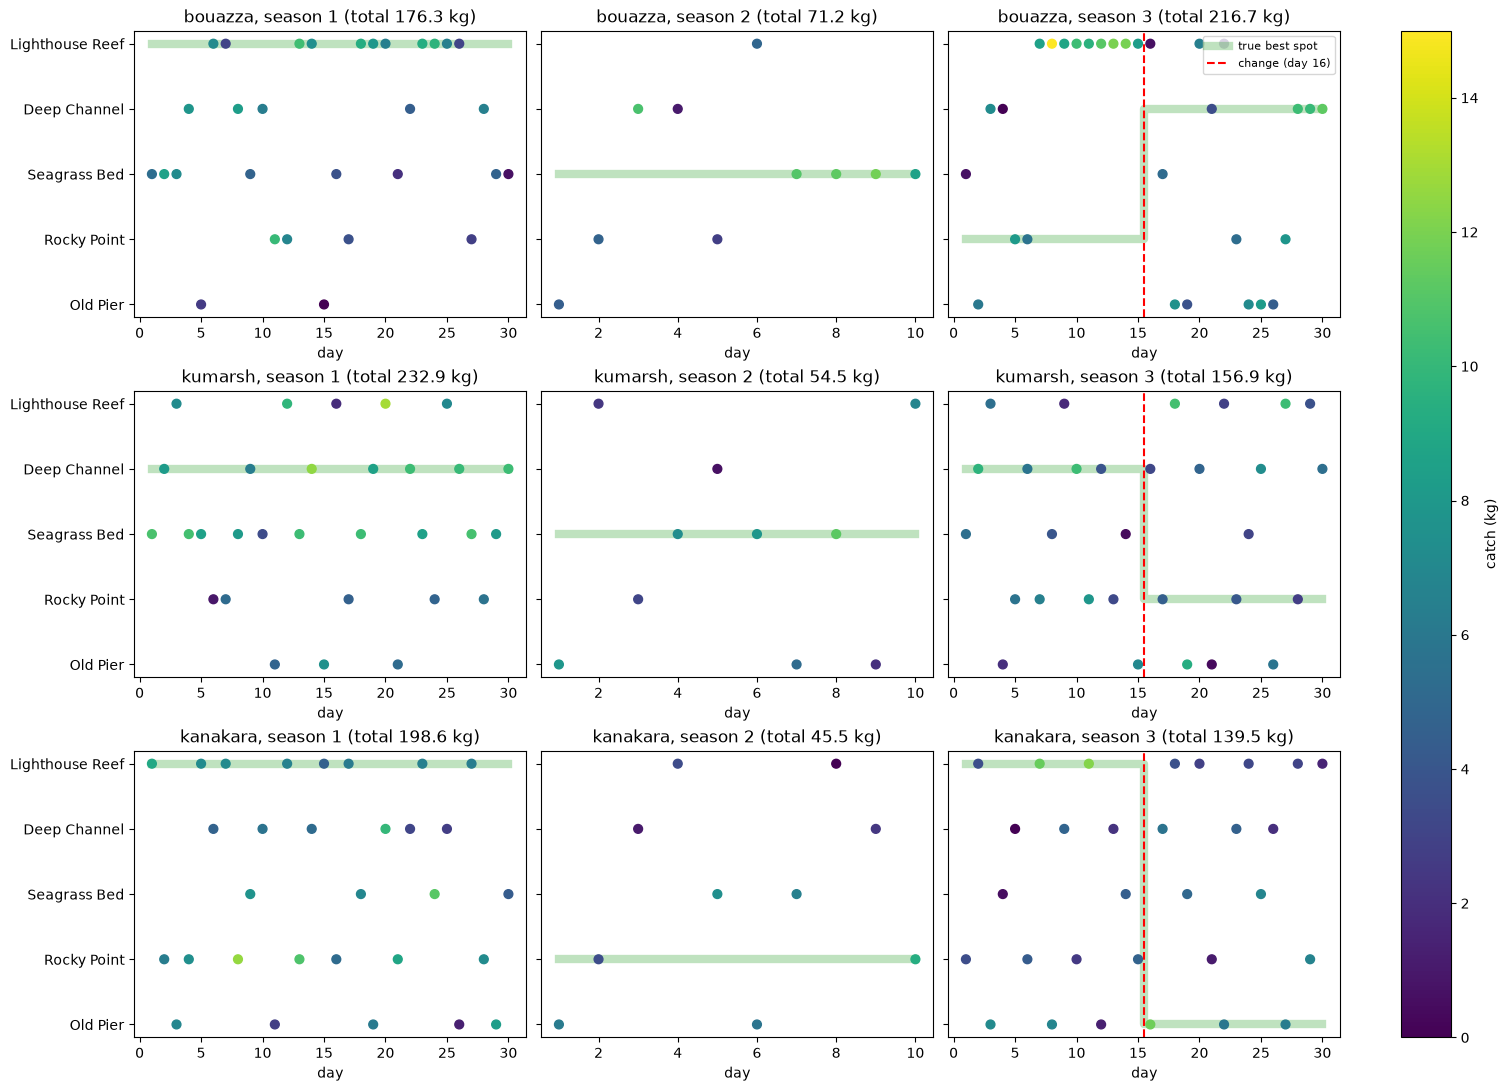

In [7]:
fig, axes = plt.subplots(len(logs), 3, figsize=(15, 3.6 * len(logs)), sharey=True,
                         squeeze=False, layout="constrained")
for i, log in enumerate(logs):
    for j, season in enumerate((1, 2, 3)):
        ax = axes[i, j]
        bay = member_bays[(log["student_id"], season)]
        truth = bay.reveal()
        days = np.arange(1, bay.days + 1)
        best = [int(np.argmax(true_means_on_day(truth, d))) for d in days]
        ax.step(days, best, where="mid", color="tab:green", lw=6, alpha=0.3, label="true best spot")
        spots = [spot for spot, _ in bay.history]
        sc = ax.scatter(days, spots, c=[catch for _, catch in bay.history], cmap="viridis",
                        vmin=0, vmax=15, s=40, zorder=3)
        if "change_day" in truth:
            ax.axvline(truth["change_day"] - 0.5, color="red", ls="--", label="change (day 16)")
        ax.set_title(f"{log['student_id']}, season {season} (total {bay.total} kg)")
        ax.set_xlabel("day")
        ax.set_yticks(range(len(SPOTS)), SPOTS)
        if i == 0 and j == 2:
            ax.legend(loc="upper right", fontsize=8)
fig.colorbar(sc, ax=axes, label="catch (kg)")
save_figure(fig, "human_choices.png")
plt.show()

**Observations.**

- **Soulaimen (bouazza)**, Season 1: started at Seagrass Bed, left after low catches and tried every spot (18 switches). He spent 11 of 30 days at the best spot, Lighthouse Reef, and has a regret of 38.7 kg. His note says he moved below about 6.5 kg and sometimes tried a bad spot. He did try bad spots, but he did not keep to a fixed threshold: he stayed after a catch of 4.7 kg and moved after one of 8.3 kg.
- Soulaimen, Season 2: tried four spots on days 1 to 6, then fished at Seagrass Bed (the best spot, 9.9 kg) from day 7 to day 10, as his note says.
- Soulaimen, Season 3: he kept to the 6 kg rule of his note. His lowest catch before staying was 7.1 kg. He stayed at Lighthouse Reef from day 7 to day 16. Its average (9.6 kg) was almost equal to the best (Rocky Point, 9.7 kg), so his choice was nearly perfect before the change, even though it does not count as days at the best spot. He left on day 17 and found the new best spot, Deep Channel, on day 21.
- **Shubham (kumarsh)**, Season 1: he switched spot on 27 of 29 days. His note says he stayed in the centre where he first caught most. He did visit Seagrass Bed most often (10 days), but the best spot was Deep Channel (9.9 kg), visited on 7 days. His play does not match his note.
- Shubham, Season 2: he tried all 5 spots on days 1 to 5, as his note says, but then he did not stay at the best one (Seagrass Bed): 9 switches in 10 days.
- Shubham, Season 3: random choices (29 switches), which matches his note.
- **Adhitya (kanakara)**, Season 1: changed spot every day (29 switches), whatever the catch, and tried every spot. He spent 8 of 30 days at the best spot, Lighthouse Reef (9.6 kg), and has a regret of 66.0 kg. His note says random choice, but his play is closer to a sweep than to uniform random choice (agreement table below).
- Adhitya, Season 2: two sweeps. Days 1 to 5 visit every spot once, and days 6 to 10 again. This is the "ordered way" of his note. His regret (14.8 kg) is the lowest of the team in Season 2, but not thanks to his decisions: the spots of this bay are close, and the random agent has the same mean regret on it (Section 2).
- Adhitya, Season 3: changed spot every day again, whatever the catch. His regret (121.0 kg) is the highest of the team. His note names no method and blames bad luck. Regret leaves luck out: his 121.0 kg is close to the random agent's mean on this bay (113.5 kg, Section 2).
- Totals mislead: Shubham's Season 1 total (232.9 kg) is higher than Soulaimen's (176.3 kg), but so is his regret (48.4 against 38.7 kg). His bay was richer (best possible 297 kg against 213 kg). Adhitya's Season 1 total (198.6 kg) is also above Soulaimen's, with a regret of 66.0 kg.

### Task 2: the strategies as precise rules

All rules are agents in `agents.py`, and their docstrings give every detail.

- **Threshold rule** (`ThresholdRuleAgent`, Soulaimen's notes, log `bouazza`):
  1. Start at Seagrass Bed ("in the middle").
  2. Stay while the last catch is at least 6 kg.
  3. On a day it leaves, test a spot not visited for 8 days or more, if there is one (Season 3 note).
  4. Otherwise go to the other spot with the best average so far. If no other spot has been visited yet, go to the spot unvisited longest.
- **Explore then commit** (`ExploreThenCommitAgent`, Shubham's Season 1 and 2 notes, log `kumarsh`): fish once at each spot, then always at the spot with the best average so far.
- **Sweep** (`SweepAgent`, Adhitya's Season 2 note "in a ordered way", log `kanakara`): each day, a random spot not yet visited in the current sweep. Once all 5 spots are visited, a new sweep starts.
- **Random** (`RandomAgent`): Shubham's Season 3 note and Adhitya's Season 1 note say they chose randomly.

A rule is precise when it can be applied to any log. To check, we feed each rule a member's own history and ask, every day, which spot it would choose next. **Agreement** is the share of days 2 to the end where the rule picks the member's actual spot. Random choice agrees on about 20% of days.

In [8]:
def agreement(agent, log, season):
    """Share of days 2 to the end on which agent picks the member's spot.

    The agent is fed the member's own spots and catches, so each day it
    answers: what would this rule do next, given what the member saw?
    """
    agent.reset()
    spots, catches = choices(log, season)
    hits = 0
    for day, (spot, catch) in enumerate(zip(spots, catches)):
        if day > 0:
            hits += agent.choose() == spot
        agent.update(spot, catch)
    return hits / (len(spots) - 1)


RULES = {"threshold rule": lambda s: ThresholdRuleAgent(seed=s),
         "explore then commit": lambda s: ExploreThenCommitAgent(seed=s),
         "sweep": lambda s: SweepAgent(seed=s),
         "random": lambda s: RandomAgent(seed=s)}
rows = []
for log in logs:
    for season in (1, 2, 3):
        row = {"member": log["student_id"], "season": season}
        for name, make in RULES.items():
            row[name] = float(np.mean([agreement(make(s), log, season) for s in range(20)]))
        rows.append(row)
print_table(rows, "Agreement of each rule with each member (share of days, 20 agent seeds)", digits=2)

Agreement of each rule with each member (share of days, 20 agent seeds)
  member  season  threshold rule  explore then commit  sweep  random
 bouazza       1            0.45                 0.34   0.20    0.19
 bouazza       2            0.57                 0.56   0.21    0.17
 bouazza       3            0.66                 0.48   0.17    0.21
 kumarsh       1            0.21                 0.17   0.27    0.18
 kumarsh       2            0.11                 0.56   0.31    0.21
 kumarsh       3            0.36                 0.31   0.28    0.21
kanakara       1            0.07                 0.21   0.30    0.15
kanakara       2            0.11                 0.33   0.49    0.17
kanakara       3            0.22                 0.28   0.37    0.19



**Observations.**

- Soulaimen: the threshold rule, written from his own notes, fits him best in every season (45%, 57% and 66% of days), well above random (15% to 21% in every row). Explore then commit is close in Season 2 (56%), because both rules stay at a spot while it gives good catches.
- Shubham: in Season 1 these two rules are at the random level (21% and 17%), so his note does not describe his play. In Season 2 explore then commit agrees on 56% of days, which is his own description. The sweep also fits him better than random (27% to 31%), since he changed spot almost every day.
- Adhitya: the sweep agrees best in every season (30%, 49% and 37%). In Season 2 this is his note. His Season 1 note says random and his Season 3 note names no method, but in both seasons his play is closer to a sweep than to uniform random choice.
- A rule written from a note is only as good as the note. The agreement rate shows where the two differ.

### Task 2: the best human strategy

The best rule is the one that makes the best decisions, so we compare regret, not totals, over the 1000 tuning bays of every season. The winner becomes `HumanRuleAgent` in `agents.py`.

In [9]:
rows = []
for season in (1, 2, 3):
    row = {"season": season}
    for name, make in RULES.items():
        r = describe(evaluate(make, season, TUNE_SEEDS)["regret"])
        row[f"{name} regret"] = r["mean"]
        row[f"{name} se"] = r["se"]
    rows.append(row)
print_table(rows, "Mean regret of the human rules on the tuning bays (kg)")
totals = [{"rule": name, "regret summed over the 3 seasons": sum(row[f"{name} regret"] for row in rows)}
          for name in RULES]
print_table(totals, "Total of the three seasons (kg)")
best_rule = min(totals, key=lambda row: row["regret summed over the 3 seasons"])["rule"]
print("Rule with the lowest total regret:", best_rule)

# Catches as FishingBay makes them: normal noise with sd SD, rounded half up to 0.1 kg, then clipped at 0.
leave_below = ThresholdRuleAgent().leave_below
noise_rng = np.random.default_rng(0)
for mean in (9.9, 8.0):
    catches = np.maximum(0.0, np.floor(noise_rng.normal(mean, SD, 1_000_000) * 10 + 0.5) / 10)
    print(f"A spot with true average {mean} kg gives less than {leave_below} kg "
          f"on {np.mean(catches < leave_below):.1%} of days")

Mean regret of the human rules on the tuning bays (kg)
season  threshold rule regret  threshold rule se  explore then commit regret  explore then commit se  sweep regret  sweep se  random regret  random se
     1                   41.7                0.7                        23.9                     0.5          79.4       0.9           79.9        0.9
     2                   19.4                0.5                        16.5                     0.2          26.9       0.3           26.7        0.4
     3                   45.5                0.6                        49.3                     0.9          78.8       0.6           78.3        0.7

Total of the three seasons (kg)
               rule  regret summed over the 3 seasons
     threshold rule                             106.6
explore then commit                              89.8
              sweep                             185.1
             random                             184.8

Rule with the lowest total regret: ex

**Observations.**

- Explore then commit has the lowest regret summed over the three seasons (89.8 against 106.6 kg for the threshold rule). It wins Seasons 1 and 2 (23.9 against 41.7, 16.5 against 19.4 kg).
- The threshold rule leaves good spots too often. With a noise of 2.5 kg, even a 9.9 kg spot gives less than 6 kg on 5.7% of days, and an 8 kg spot on 20.6%.
- Leaving quickly hurts in Seasons 1 and 2 but helps in Season 3 (45.5 against 49.3 kg). After the change, a spot that became poor gives low catches and the threshold rule leaves it. Explore then commit keeps the spot with the best average over the whole season, which still includes the days before the change.
- The sweep never uses the catches, so it is no better than random (79.4 against 79.9, 26.9 against 26.7, 78.8 against 78.3 kg). Each difference is smaller than one standard error.
- So `HumanRuleAgent` is explore then commit.

### Task 3: the measure separates decisions from luck

Two checks on the 1000 test bays of Season 1, with the random agent (no decisions at all) and the human rule:

1. **Same strategy, many bays.** For each strategy we split the spread of the total into three parts: bay luck (how good the best spot of the bay is), noise (total minus expected total), and decisions (regret).
2. **Two strategies, same bays and different bays.** How often does the random agent catch more than the human rule, and how often does it have a lower regret? Our team members each played a different bay, so the comparison across different bays (all pairs of bays) is the one that matters for comparing members.

Season 1, 1000 test bays (kg)
  strategy  mean total  sd total  sd bay luck (best)  sd noise (total - expected)  mean regret  sd regret
    random       180.9      34.8                33.6                         13.3         80.2       29.6
human rule       235.6      38.8                33.6                         13.7         24.4       17.9

Bays where random catches more than the human rule: 5.4%
Bays where random has a lower regret than the human rule: 3.7%
Different bays (all pairs): random catches more than the human rule in 14.8% of pairs, has a lower regret in 4.9%
Correlation of the human rule's total with bay quality: 0.81
Correlation of the human rule's regret with bay quality: 0.13


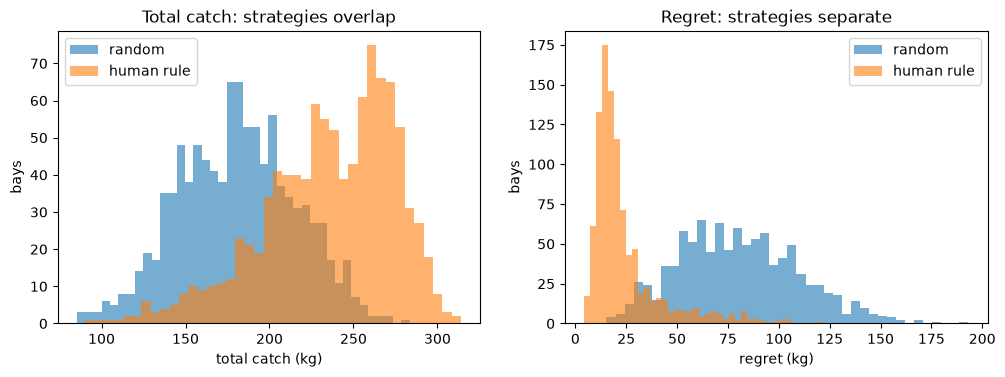

In [10]:
strategies = {"random": lambda s: RandomAgent(seed=s), "human rule": lambda s: HumanRuleAgent(seed=s)}
luck_test = {name: evaluate(make, 1, TEST_SEEDS) for name, make in strategies.items()}
rows = []
for name, res in luck_test.items():
    rows.append({"strategy": name, "mean total": res["total"].mean(), "sd total": res["total"].std(ddof=1),
                 "sd bay luck (best)": res["best"].std(ddof=1),
                 "sd noise (total - expected)": (res["total"] - res["expected"]).std(ddof=1),
                 "mean regret": res["regret"].mean(), "sd regret": res["regret"].std(ddof=1)})
print_table(rows, "Season 1, 1000 test bays (kg)")

rand, rule = luck_test["random"], luck_test["human rule"]
print(f"Bays where random catches more than the human rule: {np.mean(rand['total'] > rule['total']):.1%}")
print(f"Bays where random has a lower regret than the human rule: {np.mean(rand['regret'] < rule['regret']):.1%}")
print(f"Different bays (all pairs): random catches more than the human rule in "
      f"{np.mean(rand['total'][:, None] > rule['total'][None, :]):.1%} of pairs, "
      f"has a lower regret in {np.mean(rand['regret'][:, None] < rule['regret'][None, :]):.1%}")
print(f"Correlation of the human rule's total with bay quality: {np.corrcoef(rule['total'], rule['best'])[0, 1]:.2f}")
print(f"Correlation of the human rule's regret with bay quality: {np.corrcoef(rule['regret'], rule['best'])[0, 1]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, res in luck_test.items():
    axes[0].hist(res["total"], bins=40, alpha=0.6, label=name)
    axes[1].hist(res["regret"], bins=40, alpha=0.6, label=name)
axes[0].set(title="Total catch: strategies overlap", xlabel="total catch (kg)", ylabel="bays")
axes[1].set(title="Regret: strategies separate", xlabel="regret (kg)", ylabel="bays")
for ax in axes:
    ax.legend()
save_figure(fig, "luck_vs_decisions.png")
plt.show()

**Observations.**

- The spread of the total (sd 38.8 kg for the human rule) comes almost entirely from luck: bay quality (sd 33.6 kg) and noise (sd 13.7 kg). The human rule's total has a correlation of 0.81 with bay quality, but its regret only 0.13.
- On the same bays, random catches more than the human rule on 5.4% of bays, and has a lower regret on 3.7%. Pairing removes the bay luck, but noise remains.
- On different bays, which is how we compare team members, random catches more in 14.8% of pairs but has a lower regret in only 4.9%. The total often ranks a random player above a good one; regret rarely does.
- Regret is the measure we use from here on.

### Task 3: the team across the three seasons

Regret per day makes seasons of different length comparable. For Season 3, the table shows the best spot before and after the change on day 16. It also shows how many days after the change each member first fished at the new best spot, and how many of the days 16 to 30 he spent at the old and at the new best spot.

In [11]:
rows = []
for (member, season), bay in member_bays.items():
    result = season_result(bay)
    rows.append({"member": member, "season": season, "regret per day": result["regret"] / bay.days,
                 "expected / best": result["expected"] / result["best"]})
print_table(rows, "Regret per day (kg) and share of the best expected total", digits=2)

rows = []
for log in logs:
    bay = member_bays[(log["student_id"], 3)]
    truth = bay.reveal()
    change = truth["change_day"]
    old_best = int(np.argmax(truth["means"]))
    new_best = int(np.argmax(truth["means_after_change"]))
    after = [spot for spot, _ in bay.history][change - 1:]
    first_new = next((i for i, spot in enumerate(after) if spot == new_best), None)
    own = bay.history[change - 2][0]
    rows.append({"member": log["student_id"],
                 "spot before change": f"{SPOTS[own]} ({truth['means'][own]}, then {truth['means_after_change'][own]})",
                 "best before": f"{SPOTS[old_best]} ({truth['means'][old_best]})",
                 "best after": f"{SPOTS[new_best]} ({truth['means_after_change'][new_best]})",
                 "old best after change": f"{truth['means_after_change'][old_best]}",
                 "days to new best": "never" if first_new is None else first_new,
                 "days at old best (16-30)": after.count(old_best),
                 "days at new best (16-30)": after.count(new_best)})
print_table(rows, "Season 3: the change and how each member reacted")

Regret per day (kg) and share of the best expected total
  member  season  regret per day  expected / best
 bouazza       1            1.29             0.82
 bouazza       2            2.86             0.71
 bouazza       3            2.30             0.75
 kumarsh       1            1.61             0.84
 kumarsh       2            3.09             0.60
 kumarsh       3            2.02             0.73
kanakara       1            2.20             0.77
kanakara       2            1.48             0.77
kanakara       3            4.03             0.53

Season 3: the change and how each member reacted
  member               spot before change            best before          best after  old best after change  days to new best  days at old best (16-30)  days at new best (16-30)
 bouazza  Lighthouse Reef (9.6, then 2.3)      Rocky Point (9.7)  Deep Channel (8.9)                    3.5                 5                         2                         4
 kumarsh         Old Pier (6.0, then 

**Observations.**

- **Season 2 (shorter).** Soulaimen and Shubham lost about twice as much per day as in Season 1 (2.86 against 1.29 and 3.09 against 1.61 kg per day). With only 10 days, the days spent finding the best spot are a large part of the season, and there is little time left to profit from it. Adhitya is the exception: he lost less per day than in Season 1 (1.48 against 2.20 kg). His Season 2 bay has close spots: even the random agent's regret on it is only 14.8 kg (Section 2).
- **Season 3 (change).** On day 16 all averages were redrawn. In Soulaimen's bay the best spot moved from Rocky Point (9.7 kg) to Deep Channel (8.9 kg), and his spot (Lighthouse Reef) dropped to 2.3 kg. In Shubham's bay the best moved from Deep Channel (8.5 kg, now 3.8 kg) to Rocky Point (6.6 kg). In Adhitya's bay it moved from Lighthouse Reef (9.6 kg, now 2.7 kg) to Old Pier (7.7 kg).
- **Who adapted, and how fast.** Soulaimen adapted. He left Lighthouse Reef the day after the change and reached the new best spot 5 days after it, on day 21. He left it again the next day and settled there only for the last 3 days, so he spent 4 of the last 15 days at the new best spot. Shubham played at random, so he reached the new best spot after 1 day only by chance. He spent 3 of the last 15 days there, no more than random play (about 3 days). Adhitya changed spot every day, whatever the catch. He fished at Old Pier on the day of the change, by chance, then spent 3 of the last 15 days there and 5 at the old best spot. That is no better than random play, and not adaptation.

## 1. Random bays

Evaluate every agent on at least 1000 random bays for each season (1, 2 and 3), and report the distribution of the results.

**Agents compared.** All are in `agents.py`. The parameters were chosen on the tuning bays: Part II for the human rule, Section 4 for UCB's `c`, and the step-size study in Section 3.

| Name | Class and parameters | Idea |
| --- | --- | --- |
| Random | `RandomAgent` | No learning, a baseline |
| Human rule | `HumanRuleAgent` | Explore each spot once, then the best average |
| Threshold rule | `ThresholdRuleAgent` | Soulaimen's rules, the second human strategy |
| Sweep | `SweepAgent` | Adhitya's rule: every spot once per sweep, in random order, never using the catches |
| Eps-greedy 0.1 | `EpsilonGreedyAgent(epsilon=0.1)` | Sample averages, 10% random days |
| Optimistic | `EpsilonGreedyAgent(epsilon=0, alpha=0.3, initial_value=15)` | Greedy, optimistic start forces exploration |
| UCB c=2 | `UCBAgent(c=2)` | Confidence bonus, sample averages |
| UCB c=3 a=0.3 | `UCBAgent(c=3, alpha=0.3)` | Confidence bonus, constant step size for change |

In [12]:
AGENTS = {
    "Random": lambda s: RandomAgent(seed=s),
    "Human rule": lambda s: HumanRuleAgent(seed=s),
    "Threshold rule": lambda s: ThresholdRuleAgent(seed=s),
    "Sweep": lambda s: SweepAgent(seed=s),
    "Eps-greedy 0.1": lambda s: EpsilonGreedyAgent(epsilon=0.1, seed=s),
    "Optimistic": lambda s: EpsilonGreedyAgent(epsilon=0.0, alpha=0.3, initial_value=15.0, seed=s),
    "UCB c=2": lambda s: UCBAgent(c=2.0, seed=s),
    "UCB c=3 a=0.3": lambda s: UCBAgent(c=3.0, alpha=0.3, seed=s),
}
results = {season: {name: evaluate(make, season, TEST_SEEDS) for name, make in AGENTS.items()}
           for season in (1, 2, 3)}

for season in (1, 2, 3):
    rows = []
    for name, res in results[season].items():
        t, r = describe(res["total"]), describe(res["regret"])
        rows.append({"agent": name, "total mean": t["mean"], "total sd": t["sd"], "total p5": t["p5"],
                     "total median": t["median"], "total p95": t["p95"], "regret mean": r["mean"],
                     "regret se": r["se"], "regret p5": r["p5"], "regret median": r["median"],
                     "regret p95": r["p95"]})
    print_table(rows, f"Season {season} ({SEASON_DAYS[season]} days), {len(TEST_SEEDS)} test bays (kg)")

Season 1 (30 days), 1000 test bays (kg)
         agent  total mean  total sd  total p5  total median  total p95  regret mean  regret se  regret p5  regret median  regret p95
        Random       180.9      34.8     125.0         181.5      237.5         80.2        0.9       33.9           78.2       131.2
    Human rule       235.6      38.8     161.0         240.5      287.5         24.4        0.6        9.2           18.5        66.6
Threshold rule       218.5      42.6     143.8         219.1      288.0         41.7        0.7       10.3           39.7        77.7
         Sweep       180.4      32.8     129.0         179.0      237.2         80.5        0.9       37.8           78.6       129.0
Eps-greedy 0.1       209.1      53.8     111.8         212.8      286.5         51.6        1.4        3.0           37.5       143.7
    Optimistic       211.4      36.6     143.7         216.2      263.9         48.9        0.5       26.2           48.2        75.4
       UCB c=2       2

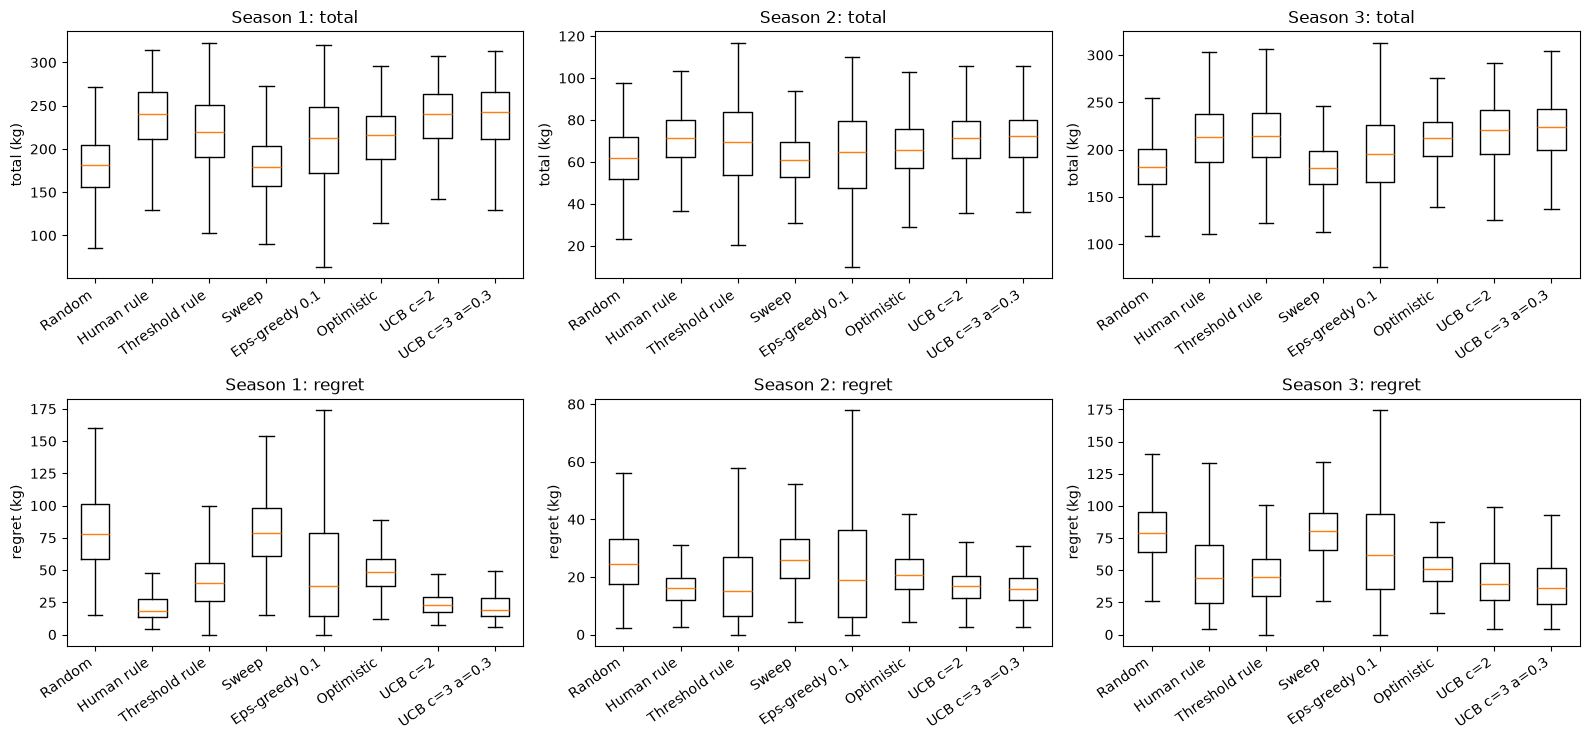

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
names = list(AGENTS)
for j, season in enumerate((1, 2, 3)):
    for i, key in enumerate(("total", "regret")):
        ax = axes[i, j]
        ax.boxplot([results[season][n][key] for n in names], showfliers=False)
        ax.set_xticks(range(1, len(names) + 1), names, rotation=35, ha="right")
        ax.set_title(f"Season {season}: {key}")
        ax.set_ylabel(f"{key} (kg)")
fig.tight_layout()
save_figure(fig, "agents_distribution.png")
plt.show()

**Observations.**

- **Season 1.** The human rule (24.4 kg), UCB c=2 (25.1 kg) and UCB c=3 a=0.3 (24.1 kg) have about the same mean regret. UCB has a shorter tail (95th percentile 46.6 kg for c=2 against 66.6 kg): explore then commit decides after a single catch per spot and sometimes commits to the wrong spot, while UCB keeps re-testing.
- **Epsilon-greedy 0.1** starts with all estimates at 0, so it keeps the first spot that gives anything and only explores on its random days. It is either very good or very bad (5th percentile 3.0 kg, 95th 143.7 kg).
- **Optimistic** (start at 15 kg, step size 0.3) explores for too long in a 30-day season.
- **Sweep** (Adhitya's rule) never uses the catches, so it is no better than random (80.5 against 80.2 kg in Season 1, 26.4 against 25.9 in Season 2, 80.4 against 79.8 in Season 3). Its spread is a little smaller (Season 3: 95th percentile 113.4 against 119.6 kg), because it visits every spot equally often.
- **Season 3** separates the agents: UCB with a constant step size has the lowest regret (39.4 kg).
- The total catch shows the same order but with much more spread, since it includes luck.

## 2. Your team's bays

Run your agents on the bays played by your team members and compare with their results.
`FishingBay.from_log(log, season)` rebuilds the exact bay a member played, with the same catch on every day.

Each agent plays each member's real bay. Agents that use randomness are run with 100 agent seeds on the same bay, and the tables give the average. "Beats member" is the share of agent seeds whose total is higher than the member's.

In [14]:
rows_total, rows_regret, rows_beats = [], [], []
for log in logs:
    member = log["student_id"]
    for season in (1, 2, 3):
        human = season_result(member_bays[(member, season)])
        row_t = {"member": member, "season": season, "member total": human["total"]}
        row_r = {"member": member, "season": season, "member regret": human["regret"]}
        row_b = {"member": member, "season": season}
        for name, make in AGENTS.items():
            bay = FishingBay.from_log(log, season)
            res = []
            for agent_seed in range(N_AGENT_SEEDS):
                play(make(agent_seed), bay)
                res.append(season_result(bay))
            totals = np.array([r["total"] for r in res])
            row_t[name] = totals.mean()
            row_r[name] = float(np.mean([r["regret"] for r in res]))
            row_b[name] = f"{np.mean(totals > human['total']):.0%}"
        rows_total.append(row_t)
        rows_regret.append(row_r)
        rows_beats.append(row_b)
print_table(rows_total, "Team bays: mean total of each agent (kg)")
print_table(rows_regret, "Team bays: mean regret of each agent (kg)")
print_table(rows_beats, "Team bays: share of agent seeds with a higher total than the member")

# Random and the sweep never use the catches, so they do not count as learning agents
learning = [name for name in AGENTS if name not in ("Random", "Sweep")]
most_better = sum(sum(row[name] < row["member regret"] for name in learning) > len(learning) / 2
                  for row in rows_regret)
print(f"Team bays where most learning agents have a lower regret than the member: "
      f"{most_better} of {len(rows_regret)}")

Team bays: mean total of each agent (kg)
  member  season  member total  Random  Human rule  Threshold rule  Sweep  Eps-greedy 0.1  Optimistic  UCB c=2  UCB c=3 a=0.3
 bouazza       1         176.3   164.9       186.1           180.5  164.8           180.2       175.7    191.2          192.3
 bouazza       2          71.2    60.5        77.5           102.6   59.1            63.6        73.4     80.3           78.3
 bouazza       3         216.7   173.9       175.6           198.8  173.6           180.9       203.0    201.5          215.2
 kumarsh       1         232.9   241.9       266.4           285.3  241.3           263.6       264.8    272.7          276.5
 kumarsh       2          54.5    46.1        56.6            67.7   46.4            48.4        53.1     56.7           60.0
 kumarsh       3         156.9   156.5       168.3           161.8  158.6           173.2       172.1    188.3          196.3
kanakara       1         198.6   218.6       270.6           242.4  220.4    

**Observations.**

- On 8 of the 9 team bays, most learning agents have a lower regret than the member. Against Shubham (kumarsh), the human rule and both UCB agents beat his total on 67% to 100% of agent seeds in every season, and against Adhitya (kanakara) on 81% to 100%.
- Soulaimen's (bouazza) Season 3 is the exception. His regret (69.0 kg) is matched only by UCB c=3 a=0.3 (67.7 kg), which beats his total on 57% of agent seeds. Other agents do worse on this bay. Its two best spots before the change were almost equal (9.7 and 9.6 kg), and he left his spot the day after the change.
- The threshold rule looks very good in Season 2 on all three bays (regret 0.0, 12.5 and 10.6 kg). That is because it starts at Seagrass Bed, which happened to be the best spot in every member's Season 2 bay (tied with Rocky Point for Adhitya). On 1000 random bays it is worse than the human rule (Section 1). A few bays are not enough to judge a strategy.

## 3. Seasons 2 and 3

Identify the best agent for Season 2 and for Season 3, and explain why.
`FishingBay(season, seed, days=..., shift_day=...)` lets you experiment with longer seasons.

The best agent of a season is the one with the lowest mean regret on the test bays. All agents play the same bays, so we compare each agent with the best one bay by bay (paired difference). A difference larger than about 2 standard errors is unlikely to be chance.

In [15]:
for season in (2, 3):
    ranked = sorted(results[season], key=lambda n: results[season][n]["regret"].mean())
    best = ranked[0]
    print(f"Season {season}: best agent is {best} "
          f"(mean regret {results[season][best]['regret'].mean():.1f} kg)")
    for other in ranked[1:4]:
        d = describe(results[season][other]["regret"] - results[season][best]["regret"])
        print(f"   {other}: {d['mean']:+.1f} kg more regret (paired se {d['se']:.1f})")
    print()

Season 2: best agent is UCB c=3 a=0.3 (mean regret 16.4 kg)
   Human rule: +0.0 kg more regret (paired se 0.2)
   UCB c=2: +0.7 kg more regret (paired se 0.1)
   Threshold rule: +2.3 kg more regret (paired se 0.5)

Season 3: best agent is UCB c=3 a=0.3 (mean regret 39.4 kg)
   UCB c=2: +4.1 kg more regret (paired se 0.5)
   Threshold rule: +6.1 kg more regret (paired se 0.8)
   Human rule: +10.0 kg more regret (paired se 0.8)



**Why.** The mean regret on each day, over the test bays, shows where each agent loses. In Season 2 the first days of exploration are a large part of the season. In Season 3, regret jumps on day 16, and only agents that keep re-testing spots and weight recent catches recover.

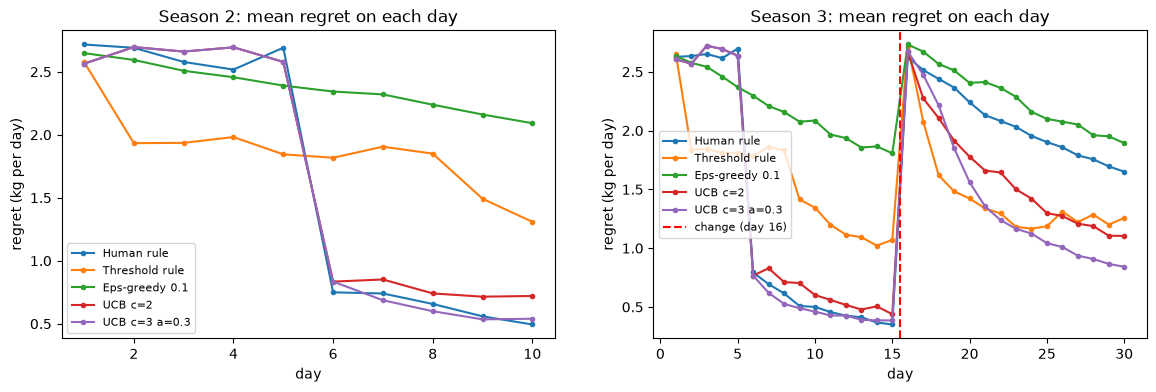

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, season in zip(axes, (2, 3)):
    for name in ("Human rule", "Threshold rule", "Eps-greedy 0.1", "UCB c=2", "UCB c=3 a=0.3"):
        daily = results[season][name]["daily"].mean(axis=0)
        ax.plot(np.arange(1, len(daily) + 1), daily, marker="o", ms=3, label=name)
    if season == 3:
        ax.axvline(15.5, color="red", ls="--", label="change (day 16)")
    ax.set(title=f"Season {season}: mean regret on each day", xlabel="day", ylabel="regret (kg per day)")
    ax.legend(fontsize=8)
save_figure(fig, "daily_regret.png")
plt.show()

**Step size for the change.** On the tuning bays of Season 3, UCB with `c = 3` and different step sizes. `None` is the sample average.

In [17]:
rows = []
for alpha in (None, 0.1, 0.2, 0.3, 0.5):
    r = describe(evaluate(lambda s: UCBAgent(c=3.0, alpha=alpha, seed=s), 3, TUNE_SEEDS)["regret"])
    rows.append({"alpha": str(alpha), "regret mean": r["mean"], "regret se": r["se"]})
print_table(rows, "Season 3, UCB c=3, tuning bays (kg)")

Season 3, UCB c=3, tuning bays (kg)
alpha  regret mean  regret se
 None         42.8        0.6
  0.1         55.6        0.9
  0.2         43.3        0.7
  0.3         38.8        0.6
  0.5         38.0        0.5



**Longer seasons.** The same comparison when the season lasts longer: Season 1 with 10 days (that is Season 2), 30 days and 100 days, and Season 3 with 200 days and the change on day 101. These use 300 test bays to keep the run short.

In [18]:
LONG_SEEDS = range(1000, 1300)
LONG_AGENTS = ("Human rule", "Eps-greedy 0.1", "UCB c=2", "UCB c=3 a=0.3")
rows = []
for label, season, options in (("S1, 10 days", 1, {"days": 10}), ("S1, 30 days", 1, {"days": 30}),
                               ("S1, 100 days", 1, {"days": 100}),
                               ("S3, 200 days, change 101", 3, {"days": 200, "shift_day": 101})):
    row = {"season": label}
    for name in LONG_AGENTS:
        res = evaluate(AGENTS[name], season, LONG_SEEDS, **options)
        row[name] = res["regret"].mean() / options["days"]
    rows.append(row)
print_table(rows, "Mean regret per day (kg), 300 test bays", digits=2)

Mean regret per day (kg), 300 test bays
                  season  Human rule  Eps-greedy 0.1  UCB c=2  UCB c=3 a=0.3
             S1, 10 days        1.65            2.17     1.69           1.64
             S1, 30 days        0.80            1.71     0.83           0.76
            S1, 100 days        0.45            1.05     0.36           0.47
S3, 200 days, change 101        1.31            1.47     0.83           0.53



**Observations.**

- **Season 2.** UCB c=3 a=0.3 (16.4 kg) and the human rule (16.4 kg) are tied (paired difference 0.0, se 0.2), just ahead of UCB c=2 (+0.7 kg, se 0.1). With 10 days, one catch per spot followed by commitment is about the best possible: there is no time to re-test. We name UCB c=3 a=0.3 as the best agent, equal with the human rule.
- **Season 3.** UCB c=3 a=0.3 is best (39.4 kg), ahead of UCB c=2 by 4.1 kg (paired se 0.5) and of the human rule by 10.0 kg (se 0.8). The daily regret figure shows why. All agents jump on day 16, but the constant step size forgets old catches and the bonus re-tests spots, so it recovers fastest. The human rule never re-tests a spot it judged bad, so it recovers slowly.
- **Step size.** On the tuning bays, alpha 0.3 and 0.5 are within one standard error (38.8 and 38.0 kg), and both beat the sample average (42.8 kg). We kept 0.3. Alpha 0.1 is worse (55.6 kg): estimates start at 0 and take too long to reach the true averages.
- **Longer seasons.** In a stationary 100-day season, UCB with sample averages has the lowest regret per day (0.36 kg). With a change in a 200-day season, the constant step size matters even more (0.53 against 0.83 kg per day for UCB c=2).

## 4. One parameter

Study the effect of one parameter of one method.

**Method and parameter.** UCB (`UCBAgent`, sample averages) and its exploration strength `c`, from 0 (pure greedy after one visit of each spot) to 8, in every season, on the 1000 tuning bays. The error bars are 2 standard errors.

UCB: mean regret against c, tuning bays (kg)
  c  S1 regret  S2 regret  S3 regret
0.0       23.3       16.7       47.3
0.5       22.9       16.7       46.2
1.0       23.2       16.8       44.7
2.0       25.1       17.2       43.3
3.0       28.3       17.6       42.8
5.0       37.0       18.8       45.4
8.0       48.5       20.7       53.4

Season 1: lowest mean regret at c = 0.5
Season 2: lowest mean regret at c = 0.0
Season 3: lowest mean regret at c = 3.0


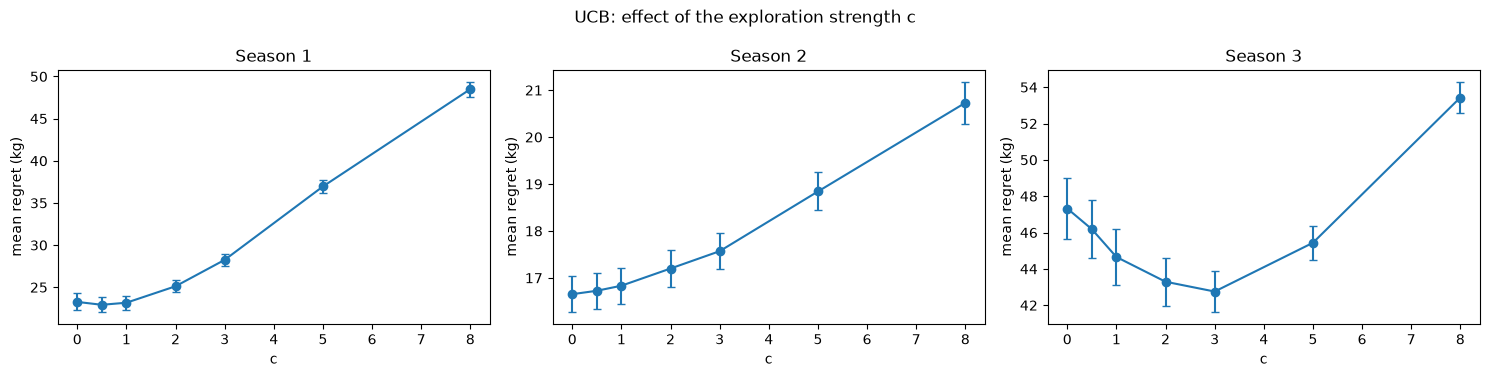

In [19]:
C_VALUES = [0.0, 0.5, 1.0, 2.0, 3.0, 5.0, 8.0]
c_study = {season: [describe(evaluate(lambda s: UCBAgent(c=c, seed=s), season, TUNE_SEEDS)["regret"])
                    for c in C_VALUES] for season in (1, 2, 3)}

rows = [{"c": c, **{f"S{season} regret": c_study[season][i]["mean"] for season in (1, 2, 3)}}
        for i, c in enumerate(C_VALUES)]
print_table(rows, "UCB: mean regret against c, tuning bays (kg)")
for season in (1, 2, 3):
    best = C_VALUES[int(np.argmin([d["mean"] for d in c_study[season]]))]
    print(f"Season {season}: lowest mean regret at c = {best}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, season in zip(axes, (1, 2, 3)):
    means = [d["mean"] for d in c_study[season]]
    errors = [2 * d["se"] for d in c_study[season]]
    ax.errorbar(C_VALUES, means, yerr=errors, marker="o", capsize=3)
    ax.set(title=f"Season {season}", xlabel="c", ylabel="mean regret (kg)")
fig.suptitle("UCB: effect of the exploration strength c")
fig.tight_layout()
save_figure(fig, "ucb_c_sweep.png")
plt.show()

**Observations.**

- With c = 0, UCB tries each spot once and then is greedy, which is the human rule (23.3 kg, against 23.9 kg in Part II).
- In Seasons 1 and 2 the regret is flat for c from 0 to 1 and rises for larger c (48.5 kg at c = 8 in Season 1): the bonus then sends the agent back to spots it already knows are bad.
- In Season 3 the best value is c = 3 (42.8 kg). After the change, extra re-testing is what finds the new best spot, so a higher c pays off.
- Too little exploration fails when the world changes. Too much wastes days when it does not. The best c depends on the season.

## 5. Part IV (optional): contextual bay

`ContextualBay(seed)` lasts 300 days. Each morning, your agent receives the conditions
`x = [wind_kmh, waves_m, tide_m]` before choosing a spot. Contextual agents are subclasses of
`ContextualAgent` in `agents.py`.

In [20]:
bay = ContextualBay(seed=0)
total = play(RandomContextualAgent(seed=0), bay)
print(f"Random contextual agent: {total} kg over {bay.days} days")

Random contextual agent: 1945.7 kg over 300 days


**Agents.** `LinearRegressionAgent` fits one ridge linear regression per spot (catch against wind, waves and tide) from its own observations, and scores each spot by its predicted catch for today's conditions.

- `epsilon = 0, bonus = 0`: acts only on its predictions.
- `epsilon > 0`: also picks a random spot on that share of days (epsilon-greedy).
- `bonus > 0`: adds `bonus * sqrt(z^T A^-1 z)` to each prediction, an upper confidence bound that is large where a spot has few observations in conditions like today's. This is the contextual form of UCB (LinUCB).

The best Part III agent is the one with the lowest Season 1 test regret in Section 1, run through `ContextFreeAgent`, which ignores the conditions. Regret is measured against the best spot for each day's conditions.

**Bonus weight.** First we choose `bonus` on 100 contextual tuning bays (seeds 1000 to 1099). The comparison then uses the next 200 bays (seeds 1100 to 1299).

In [21]:
CONTEXT_TUNE_SEEDS = range(1000, 1100)
CONTEXT_SEEDS = range(1100, 1300)


def evaluate_contextual(make_agent, seeds):
    """Play make_agent(seed) on ContextualBay(seed) for every seed.

    Returns totals, regrets, the share of days at the most used spot, and the spots.
    """
    out = {"total": [], "regret": [], "top_share": [], "spots": []}
    for seed in seeds:
        bay = ContextualBay(seed=seed)
        play(make_agent(seed), bay)
        chosen, best = chosen_and_best_means(bay)
        spots = np.array([spot for _, spot, _ in bay.history])
        out["total"].append(bay.total)
        out["regret"].append((best - chosen).sum())
        out["top_share"].append(np.bincount(spots, minlength=len(SPOTS)).max() / len(spots))
        out["spots"].append(spots)
    return {k: np.array(v) for k, v in out.items()}


rows = []
for bonus in (0.0, 2.0, 4.0, 6.0, 8.0, 10.0, 12.0):
    r = describe(evaluate_contextual(lambda s: LinearRegressionAgent(bonus=bonus, seed=s),
                                     CONTEXT_TUNE_SEEDS)["regret"])
    rows.append({"bonus": bonus, "regret mean": r["mean"], "regret se": r["se"]})
print_table(rows, "LinearRegressionAgent: regret against bonus, contextual tuning bays (kg)")

LinearRegressionAgent: regret against bonus, contextual tuning bays (kg)
bonus  regret mean  regret se
  0.0       1066.5       82.4
  2.0        655.6       54.4
  4.0        296.2       33.2
  6.0        125.0       11.2
  8.0        104.5        7.4
 10.0        127.6        3.6
 12.0        160.9        3.5



In [22]:
best_part3 = min(AGENTS, key=lambda n: results[1][n]["regret"].mean())
print("Best Part III agent (Season 1 test regret):", best_part3)

CONTEXT_AGENTS = {
    "Random": lambda s: RandomContextualAgent(seed=s),
    f"{best_part3} (no context)": lambda s: ContextFreeAgent(AGENTS[best_part3](s)),
    "Linear, predictions only": lambda s: LinearRegressionAgent(seed=s),
    "Linear, epsilon 0.1": lambda s: LinearRegressionAgent(epsilon=0.1, seed=s),
    "Linear, bonus 8 (LinUCB)": lambda s: LinearRegressionAgent(bonus=8.0, seed=s),
}
context_results = {name: evaluate_contextual(make, CONTEXT_SEEDS) for name, make in CONTEXT_AGENTS.items()}
rows = []
for name, res in context_results.items():
    t, r = describe(res["total"]), describe(res["regret"])
    rows.append({"agent": name, "total mean": t["mean"], "regret mean": r["mean"], "regret se": r["se"],
                 "regret median": r["median"], "regret p95": r["p95"],
                 "bays locked (90%+ one spot)": f"{np.mean(res['top_share'] >= 0.9):.0%}"})
print_table(rows, f"Contextual bay, {len(CONTEXT_SEEDS)} bays of 300 days (kg)")

fix = context_results["Linear, bonus 8 (LinUCB)"]["regret"]
for other in (f"{best_part3} (no context)", "Linear, epsilon 0.1"):
    d = describe(context_results[other]["regret"] - fix)
    print(f"{other}: {d['mean']:+.1f} kg more regret than LinUCB (paired se {d['se']:.1f})")

Best Part III agent (Season 1 test regret): UCB c=3 a=0.3


Contextual bay, 200 bays of 300 days (kg)
                     agent  total mean  regret mean  regret se  regret median  regret p95  bays locked (90%+ one spot)
                    Random      1703.7       1319.8       31.6         1276.2      2045.4                           0%
UCB c=3 a=0.3 (no context)      2734.7        239.5       11.8          212.1       541.9                          38%
  Linear, predictions only      1900.8       1098.8       65.4          946.8      2816.1                          90%
       Linear, epsilon 0.1      2633.2        344.7       15.5          292.3       818.0                          16%
  Linear, bonus 8 (LinUCB)      2867.1        105.2        3.6          101.0       174.7                          24%

UCB c=3 a=0.3 (no context): +134.2 kg more regret than LinUCB (paired se 10.9)
Linear, epsilon 0.1: +239.4 kg more regret than LinUCB (paired se 15.9)


**Is the model the problem?** After each season, we fit the same linear model to the true averages of every spot (from `bay.reveal()`) against the conditions seen that season, and choose the spot with the highest fitted average each day. This is the best a linear model could do with perfect data. Its regret shows how much is lost to the model itself, and how much to exploration.

In [23]:
def best_linear_regret(seed):
    """Regret of always choosing the best spot of a linear fit to the true averages.

    Analysis only: uses bay.reveal() after a season played by a random agent.
    """
    bay = ContextualBay(seed=seed)
    play(RandomContextualAgent(seed=seed), bay)
    table = bay.reveal()
    x = np.array([list(conditions.values()) for conditions, _, _ in bay.history])
    z = np.column_stack([np.ones(len(x)), x / LinearRegressionAgent().feature_scale])
    theta, *_ = np.linalg.lstsq(z, table, rcond=None)
    chosen = (z @ theta).argmax(axis=1)
    days = np.arange(len(x))
    return (table.max(axis=1) - table[days, chosen]).sum()


print(f"Best linear model with perfect data: mean regret "
      f"{np.mean([best_linear_regret(s) for s in CONTEXT_SEEDS]):.1f} kg over 300 days")

Best linear model with perfect data: mean regret 0.2 kg over 300 days


**When acting only on predictions fails.** We take the bay where the prediction-only agent has its largest regret. We plot its choices next to the true best spot for each day, and the choices of the LinUCB fix on the same bay.

Bay seed 1132: predictions only regret 4050.6 kg, 100% of days at Lighthouse Reef; true best spot Deep Channel on 100% of days; LinUCB regret 53.8 kg


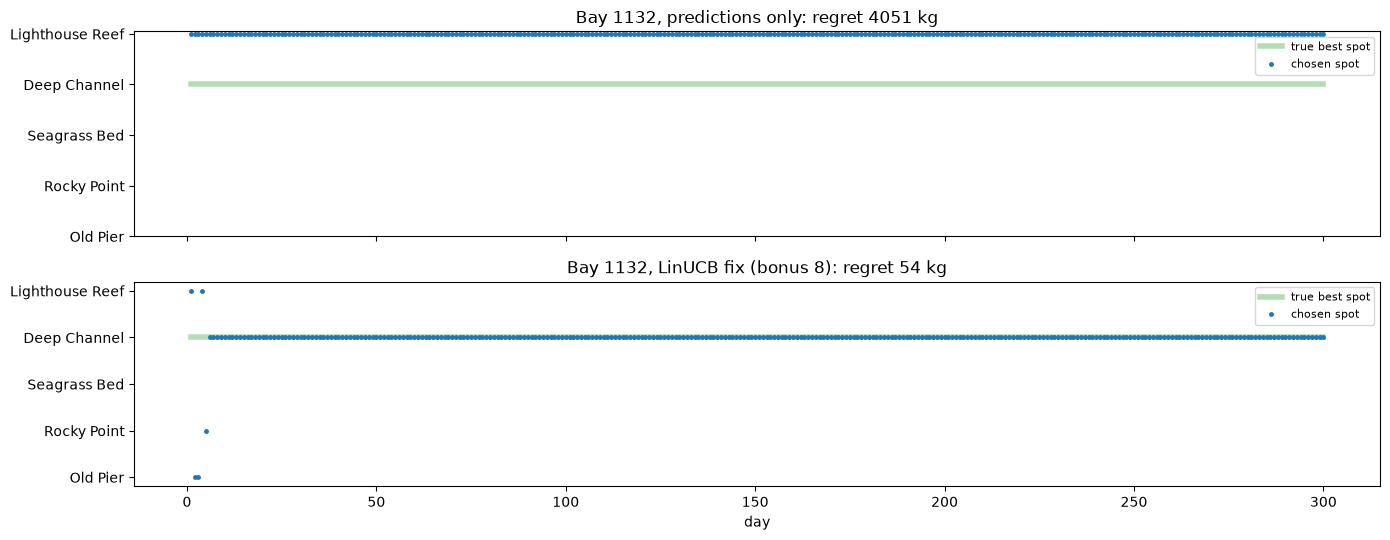

In [24]:
pure = context_results["Linear, predictions only"]
fixed = context_results["Linear, bonus 8 (LinUCB)"]
worst = int(np.argmax(pure["regret"]))
seed = CONTEXT_SEEDS[worst]
best_spots = ContextualBay(seed=seed).reveal().argmax(axis=1)
top_spot = np.bincount(pure["spots"][worst], minlength=len(SPOTS)).argmax()
main_best = np.bincount(best_spots, minlength=len(SPOTS)).argmax()
print(f"Bay seed {seed}: predictions only regret {pure['regret'][worst]:.1f} kg, "
      f"{pure['top_share'][worst]:.0%} of days at {SPOTS[top_spot]}; "
      f"true best spot {SPOTS[main_best]} on {np.mean(best_spots == main_best):.0%} of days; "
      f"LinUCB regret {fixed['regret'][worst]:.1f} kg")

fig, axes = plt.subplots(2, 1, figsize=(14, 5.5), sharex=True)
for ax, (label, res) in zip(axes, (("predictions only", pure), ("LinUCB fix (bonus 8)", fixed))):
    days = np.arange(1, len(best_spots) + 1)
    ax.step(days, best_spots, where="mid", color="tab:green", lw=4, alpha=0.35, label="true best spot")
    ax.plot(days, res["spots"][worst], "o", ms=2.5, color="tab:blue", label="chosen spot")
    ax.set_yticks(range(len(SPOTS)), SPOTS)
    ax.set_title(f"Bay {seed}, {label}: regret {res['regret'][worst]:.0f} kg")
    ax.legend(loc="upper right", fontsize=8)
axes[1].set_xlabel("day")
fig.tight_layout()
save_figure(fig, "contextual_failure.png")
plt.show()

**Observations.**

- **Acting only on predictions fails.** On 90% of bays the prediction-only agent spends 90% or more of the days at one spot. Its mean regret (1098.8 kg) is close to random (1319.8 kg). On bay 1132 it chose Lighthouse Reef on 100% of days, while Deep Channel was best on every day. Its first catch at Lighthouse Reef made that prediction positive while all untried spots stayed at 0 kg, so it never collected the data that would have shown its mistake.
- **The model is not the problem.** A linear fit to the true averages loses only 0.2 kg over 300 days, despite the clipping at 0. Almost all of the regret comes from how the agent explores.
- **Fixes.** Epsilon-greedy (0.1) avoids most lock-ins (16% of bays), but it pays for 30 random days per season (344.7 kg). The confidence bonus (LinUCB, bonus 8, chosen on separate tuning bays) explores only where it is uncertain. It has the lowest regret (105.2 kg) and recovers bay 1132 (53.8 kg).
- **Against Part III.** LinUCB beats the best Part III agent, UCB c=3 a=0.3 ignoring the conditions, by 134.2 kg (paired se 10.9) over 300 days. Using the conditions pays only when the agent also explores well: epsilon-greedy with the same model is worse than ignoring the conditions.